In [3]:
import numpy as np
import matplotlib.pyplot as plt
import re

Extracting Dineutron Data:

In [4]:
import os
print("current working directory:", os.getcwd())
os.chdir("C:\\Users\\shing\\OneDrive\\EinR + ResearchPaper\\EinR\\Data")
print("files here:", os.listdir())


current working directory: c:\Users\shing\OneDrive\EinR + ResearchPaper\Research Paper
files here: ['dineutron_Zjn_tNorm3_evp.h5', 'nn_deuteron_spectrum.h5', 'nn_dineutron_spectrum.h5']


In [43]:
from pathlib import Path
import re

import h5py
import numpy as np

DATA = Path("C:\\Users\\shing\\OneDrive\\EinR + ResearchPaper\\EinR\\Data\\nn_deuteron_spectrum.h5")  # Place beside this notebook.
L = 48.0
punit2 = (2 * np.pi / L) ** 2

# The fit's eight inputs: dimension-weighted A2/E averages at d²=1,3,4;
# equal A2/B1/B2 average at d²=2; both T1g levels at rest.
GROUPS = [
    ("T1g_Psq0_level0", r"$T_{1g}$, 0", [(1., (0, "T1g", 0))]),
    ("T1g_Psq0_level1", r"$T_{1g}$, 1", [(1., (0, "T1g", 1))]),
    ("A2E_Psq1_level0", r"$A_2/E$, 0", [(1/3, (1, "A2", 0)), (2/3, (1, "E", 0))]),
    ("A2E_Psq1_level1", r"$A_2/E$, 1", [(1/3, (1, "A2", 1)), (2/3, (1, "E", 1))]),
    ("A2B1B2_Psq2_level0", r"$A_2/B_1/B_2$", [
        (1/3, (2, "A2", 0)), (1/3, (2, "B1", 0)), (1/3, (2, "B2", 0))]),
    ("A2E_Psq3_level0", r"$A_2/E$", [(1/3, (3, "A2", 0)), (2/3, (3, "E", 0))]),
    ("A2E_Psq4_level0", r"$A_2/E$, 0", [(1/3, (4, "A2", 0)), (2/3, (4, "E", 0))]),
    ("A2E_Psq4_level1", r"$A_2/E$, 1", [(1/3, (4, "A2", 1)), (2/3, (4, "E", 1))]),
]

with h5py.File(DATA, "r") as h5:
    mN = np.asarray(h5["mN/E0"], dtype=float)  # [central, bootstrap ...]
    m = mN[0]
    raw_e_lab = {}
    for name, group in h5.items():
        match = re.fullmatch(r"(.+)_Psq(\d+)_level(\d+)", name)
        if match is None or not isinstance(group, h5py.Group):
            continue
        irrep, d2, level_number = match.group(1), int(match.group(2)), int(match.group(3))
        n1 = int(np.rint(group["Psq_N1"][0]))
        n2 = int(np.rint(group["Psq_N2"][0]))
        delta_e = np.asarray(group["dE_NN"], dtype=float)
        if delta_e.shape != mN.shape:
            raise ValueError(f"Bootstrap shape mismatch in {name}")
        e1 = np.sqrt(mN**2 + punit2 * n1)
        e2 = np.sqrt(mN**2 + punit2 * n2)
        raw_e_lab[(d2, irrep, level_number)] = delta_e + e1 + e2

deuteron_levels = []
for name, display, members in GROUPS:
    missing = [key for _, key in members if key not in raw_e_lab]
    if missing:
        raise KeyError(f"Cannot form {name}; missing {missing}")
    d2 = members[0][1][0]
    # Average a E_lab on each bootstrap sample, then transform to the CM frame.
    e_lab = sum(weight * raw_e_lab[key] for weight, key in members)
    e_cm_sq = e_lab**2 - punit2 * d2
    if np.any(e_cm_sq <= 0):
        raise ValueError(f"Nonpositive E_cm² for {name}")
    e_cm = np.sqrt(e_cm_sq)
    deuteron_levels.append({"name": name, "display": display, "d2": d2,
                   "Elab_boot": e_lab, "Ecm_boot": e_cm,
                   "q2_boot": e_cm_sq / 4 - mN**2})

from collections import defaultdict

by_d2 = defaultdict(list)
for lev in deuteron_levels:
    by_d2[lev["d2"]].append(lev)

for d2, group in by_d2.items():
    group.sort(key=lambda lev: lev["Ecm_boot"][0])          # ascending central energy
    for idx, lev in enumerate(group):
        lev["level_index"] = idx                         # this is what sector_keys should use

assert len(raw_e_lab) == 15 and len(deuteron_levels) == 8
print(f"{len(raw_e_lab)} raw levels -> {len(deuteron_levels)} irrep-averaged levels")
print(f"m_N = {mN[0]:.12f}; bootstrap replicas in fit slice = {len(mN[1:-1])}")
for lev in deuteron_levels:
    sigma = np.std(lev["Ecm_boot"][1:-1], ddof=1)
    print(f"d²={lev['d2']}  {lev['name']:<24} a E_cm = {lev['Ecm_boot'][0]:.6f} ± {sigma:.6f}")


15 raw levels -> 8 irrep-averaged levels
m_N = 0.702668276414; bootstrap replicas in fit slice = 4999
d²=0  T1g_Psq0_level0          a E_cm = 1.403989 ± 0.000964
d²=0  T1g_Psq0_level1          a E_cm = 1.425585 ± 0.001002
d²=1  A2E_Psq1_level0          a E_cm = 1.408834 ± 0.001002
d²=1  A2E_Psq1_level1          a E_cm = 1.431292 ± 0.001031
d²=2  A2B1B2_Psq2_level0       a E_cm = 1.412784 ± 0.001131
d²=3  A2E_Psq3_level0          a E_cm = 1.417514 ± 0.001032
d²=4  A2E_Psq4_level0          a E_cm = 1.404045 ± 0.000969
d²=4  A2E_Psq4_level1          a E_cm = 1.425763 ± 0.001003


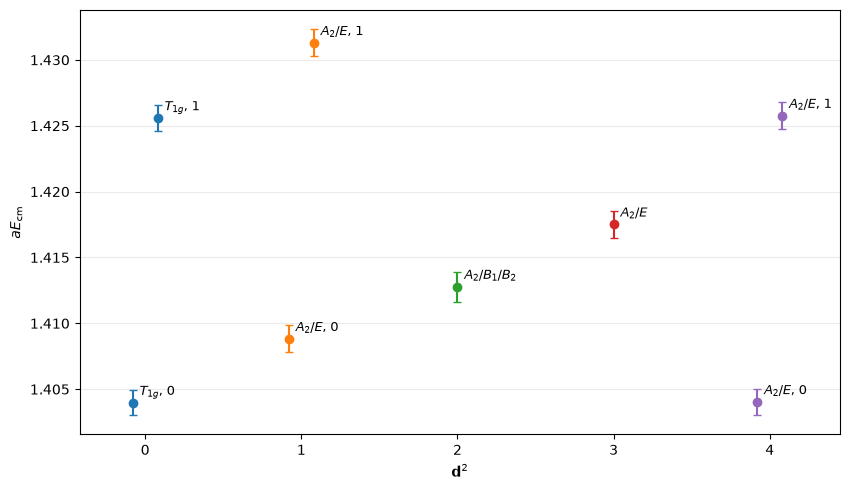

In [44]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8.6, 5.0))
for d2 in range(5):
    family = [lev for lev in deuteron_levels if lev["d2"] == d2]
    offsets = np.linspace(-0.08, 0.08, len(family)) if len(family) > 1 else [0.]
    for lev, offset in zip(family, offsets):
        x = d2 + offset
        y = lev["Ecm_boot"][0]
        sigma = np.std(lev["Ecm_boot"][1:-1], ddof=1)
        ax.errorbar(x, y, yerr=sigma, fmt="o", ms=6, capsize=3,
                    color=f"C{d2}", ecolor=f"C{d2}")
        ax.annotate(lev["display"], (x, y), xytext=(5, 5),
                    textcoords="offset points", fontsize=9)

ax.set(xlim=(-0.42, 4.45), xticks=range(5),
       xlabel=r"$\mathbf{d}^2$", ylabel=r"$a E_{\mathrm{cm}}$")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


In [7]:
print(deuteron_levels[1])

{'name': 'T1g_Psq0_level1', 'display': '$T_{1g}$, 1', 'd2': 0, 'Elab_boot': array([1.42558513, 1.4249208 , 1.42331752, ..., 1.42624478, 1.42565321,
       1.42785276], shape=(5001,)), 'Ecm_boot': array([1.42558513, 1.4249208 , 1.42331752, ..., 1.42624478, 1.42565321,
       1.42785276], shape=(5001,)), 'q2_boot': array([0.01433054, 0.01424237, 0.0142787 , ..., 0.0147911 , 0.01450363,
       0.0144625 ], shape=(5001,)), 'level_index': 1}


F-Function

In [ ]:
import itertools
from scipy import special as sp

'''
Finite-volume function
'''

twoPi = 2.0 * np.pi


# Let us work with ideentical particles throughout
xi = 1 # symmetry factor

# sqrt with branch cut aligned on positive real axis
def mySqrt(z):
   return 1j * np.sqrt( -z )

# CM momentum
def q_cm(s):
    return 0.5 * mySqrt( s - 4.0 * float(m) **2 )

# Phase space factor
def phase_space(s):
    return xi * q_cm(s) / ( 8.0 * np.pi * np.sqrt(s) )

# inner product for two list (native)
def dot(A, B):
   return np.dot(A,B) #inner1d(A,B) #np.sum( A * B, axis=1)


def inner1d(A, B):
   return np.sum( A * B, axis=1)


# Function to generate 3-tuple "n = (nx,ny,nz)" list
# subject to the constraint nx^2 + ny^2 + nz^2 <= nShell^2,
# where "nShell" indicates the number of shells
def generateIntList( nShell ):
    intList = []
    rawList = np.array(np.arange(-nShell,nShell+1))
    for i in itertools.product(rawList,rawList,rawList):
        tmpList = np.array(i)
        if ( np.dot(tmpList,tmpList) <= nShell*nShell ):
            intList.append(tmpList)

    return np.asarray(intList)

# returns the unit vector of a vector "A"
def unit_vector( A ):
    if( all( A==0 ) ):
        return A
    else:
        return A / np.sqrt( np.dot(A,A) )

# special multiply for array of arrays (A) and an array (B), used in the zeta function
def multiply( A, B ):
   nA = len(A)
   return A.reshape(nA,1) * np.tile( B, (nA,1) )
   ### First, reshape A array to 2d (1xnA), and then copy b vector nA time to make (nA x nB) array
   ### alternatively, do (A.reshape(nA,1)).dot( B.reshape(1,3) )

# returns a Lorentz boosted four vector "(A0,A)" given some boost velocity "beta"
def lorentzBoost( A0, A, beta ):
    gamma = 1.0 / np.sqrt( 1.0 - np.dot(beta,beta) )
    Apar  = multiply( A.dot( unit_vector(beta) ), unit_vector(beta) )
    Aper  = A - Apar
    A0_prime = gamma * ( A0 - A.dot( beta ) )
    A_prime  = gamma * ( Apar - multiply( A0, beta ) ) + Aper
    return A0_prime, A_prime


# cutoff function (alpha input is dimensionless)
def cutoff( qcm_sq, kcm_sq, alpha, L ):
    alpha = (L / twoPi)**2 * alpha  # convert to dimensionfull units
    return np.exp( -alpha * ( kcm_sq - qcm_sq ) )

#
# KSS Zeta function for ell = m_ell = 0, given "qcm_sq", total momentum "nP"
# This function is in units of L / 2pi, e.g. m1 -> m1 * L / (2 * pi).
#

# Finite volume function F, given Ecm (units of mass), nP, alpha (dimensionless), and L (units of mass)
# MUST call generateIntList first and use global intList from its output
#
# Note: We chose to have Ecm as input rather than E for convenience in plotting/ pole finding. Coding it the other way works too,
# we are just saving ourselves a couple transformations which are not needed for our purposes.
#
def F_function( Ecm, nP, alpha, L):
    P = twoPi * nP / L                               # P = (2*pi/L)* nP
    P_sq = np.dot(P,P)                              # P^2
    E = np.sqrt( Ecm**2 + P_sq )                    # compute E given Ecm and P
    s = Ecm**2
    eps = 1e-16
    qcm = q_cm(s+1j*eps)
    qcm_sq = qcm**2
    rho = phase_space(s+1j*eps)
    beta = P/E                                      # boost velocity

    m_sq = m**2

    k = (twoPi / L) * intList
    omega = np.sqrt( m_sq + inner1d(k,k) )
    omega_cm, k_cm = lorentzBoost( omega, k, beta )
    tmp = cutoff( qcm_sq, inner1d(k_cm,k_cm), alpha, L ) * omega_cm / omega
    tmp = tmp / ( qcm_sq - inner1d(k_cm,k_cm ) )
    sum0 = ( xi / (2.0 * Ecm * L**3) ) * np.sum( tmp )

    alpha = (L / twoPi)**2 * alpha  # convert to dimensionfull units
    z   = np.sqrt( alpha ) * qcm
    integral = ( xi / (4.0 * np.pi**2 * Ecm )) * ( ( np.sqrt( 0.25 * np.pi / alpha ) ) * np.exp( alpha * qcm_sq ) - 0.5 * np.pi * qcm * sp.erfi( z ) )

    return  1j * rho + sum0.real + integral # taking real part of sum to remove imaginary artifact at threshold



Various Constants

In [9]:
nShell = 15
alpha = 0.125

intList = generateIntList( nShell )

pole_gap = 1e-6

# Psq_to_nP = {
#     0:np.array([0,0,0]),
#     1:np.array([0,0,1]),
#     2:np.array([0,1,1]),
#     3:np.array([1,1,1]),
#     4:np.array([0,0,2])
# }

def dvec_from_d2(d2):
    nmax = int(np.ceil(np.sqrt(max(d2, 1)))) + 2
    best = None
    for nx in range(nmax + 1):
        for ny in range(nmax + 1):
            for nz in range(nmax + 1):
                v = np.array([nx, ny, nz], dtype=int)
                if int(np.dot(v, v)) == int(d2):
                    cand = tuple(sorted(v))
                    if best is None or cand < best:
                        best = cand
    if best is None:
        raise ValueError(f"No integer momentum representative found for Psq={d2}")
    return np.array(best, dtype=int)

present_Psq = sorted(set(lvl["d2"] for lvl in deuteron_levels))
Psq_to_nP = {psq: dvec_from_d2(psq) for psq in present_Psq}

m_pi = 0.3108

L_values = [48.0]

# E_min = np.min(Energy_list)-0.1
# E_max = np.max(Energy_list)+0.1


E_min = min(r["Ecm_boot"][0] for r in deuteron_levels) - 0.0003
E_max = max(r["Ecm_boot"][0] for r in deuteron_levels) + 0.0003

q2_min = ((E_min/2)**2 - m**2) 
q2_max = ((E_max/2)**2 - m**2) 
q_star_sq_grid = np.linspace(q2_min , q2_max ,2000)

Ecm_grid = 2*np.sqrt(q_star_sq_grid + m**2)

a_r_Values = np.array([
    [0.0567,-0.002,0.0],  # virtual state  -> matches Fig. 3
    [-0.18,0.32,0.05],     # virtual state  -> matches Fig. 3                             
    [ 0.18,0.0,0.0],   # shallow bound state -> matches Fig. 5
    [1.0,1.0,0.0],
    [2.0,0,0.0],
])
print(E_min,E_max)
print(q2_min,q2_max)

1.403688622275839 1.4315915641115031
-0.0011572696014247041 0.01862089493071961


Fake Energy Levels 

In [10]:
pole_cache = {}


def free_particle_poles(nP, L, m, E_min, E_max, maxShell=15):
    punit_ = 2*np.pi/L
    nP_arr = np.array(nP, dtype=float)
    Pvec = punit_*nP_arr
    P2_ = np.dot(Pvec, Pvec)
    levels = []
    for i in range(-maxShell, maxShell+1):
        for j in range(-maxShell, maxShell+1):
            for k in range(-maxShell, maxShell+1):
                n1 = np.array([i,j,k]); n2 = nP_arr - n1
                p1, p2 = punit_*n1, punit_*n2
                E_lab = float(np.sqrt(p1@p1+m**2) + np.sqrt(p2@p2+m**2))
                E_cm_sq = E_lab**2 - P2_
                if E_cm_sq <= 0:
                    continue
                E_cm = np.sqrt(E_cm_sq)
                if E_min - 0.05 < E_cm < E_max + 0.05:
                    levels.append(E_cm)
    return np.unique(np.round(levels, 10))


def free_particle_poles_cached(nP, L, m, E_min, E_max, maxShell=15):
    key = (tuple(nP), L, m, E_min, E_max, maxShell)
    if key not in pole_cache:
        raw = free_particle_poles(nP, L, m, E_min, E_max, maxShell)

        if len(raw) == 0:
            pole_cache[key] = raw
        else:
            unique = [raw[0]]
            for p in raw[1:]:
                if abs(p - unique[-1]) > 1e-5:
                    unique.append(p)
            pole_cache[key] = np.array(unique, dtype=float)
    return pole_cache[key]



In [11]:
def mySqrt_vectorized(z):
    z = np.asarray(z, dtype=complex)
    return 1j * np.sqrt(-z)

def q_cm_vectorized(s):
    return 0.5 * mySqrt_vectorized(s - 4.0 * m**2)

def M_using_a_r(Ecm, a, r, p4):
    s = Ecm**2
    qcm = q_cm_vectorized(s)
    effective_range = -1/a + 0.5* r * (qcm**2) + p4 * (qcm**4)
    return (8.0 * np.pi * np.sqrt(s)) / (xi * (effective_range - (1j * qcm)))

# def M_using_a_r(Ecm, a, r): 
#     s = Ecm**2
#     qcm = q_cm_vectorized(s)
#     effective_range = (-1/a) + 0.5 * r * (qcm**2)
#     return (8.0 * np.pi * np.sqrt(s)) / (xi * (effective_range - (1j * qcm)))

# def quantization_condition(Ecm, a, r, nP,L):
#     # eps = 1e-16
#     # s = Ecm**2 + 1j*eps
#     # qCotDelta = -1/a + 0.5*r*q_cm(s)**2
#     # Kinverse = xi * qCotDelta / (8*np.pi*Ecm)   <----- 2 ways to implment quantization condition. Comment out 1
#     # Fpv = F_function(Ecm, nP, alpha, L).real   
#     # return (Kinverse + Fpv).real
   
   
#     FValues = F_function(Ecm,nP,alpha,L)
#     MValues = M_using_a_r(Ecm,a,r)                 #<----- 2 ways to implment quantization condition. Comment out 1
#     return np.real(1/MValues + FValues)

In [12]:


# def find_zeros_in_grid(quantization_values, energies, poles,Psq):
#     zeros = []
#     for i in range(len(energies) - 1):
#         f1, f2 = quantization_values[i], quantization_values[i+1]
#         e1, e2 = energies[i], energies[i+1]
#         if not (np.isfinite(f1) and np.isfinite(f2)):
#             continue
#         if np.sign(f1) == np.sign(f2):
#             continue
#         if np.any((poles >= e1) & (poles <= e2)):
#             continue   
#         slope = (f2 - f1) / (e2 - e1)

#         root = e1 - f1/slope
#         if np.any(np.abs(root - poles) < pole_gap):
#             continue


#         zeros.append(e1 - f1/slope)
    # return np.array(zeros)

def find_zeros_in_grid(quantization_values, energies, poles, Psq):
    f1, f2 = quantization_values[:-1], quantization_values[1:]
    e1, e2 = energies[:-1], energies[1:]

    mask = np.isfinite(f1) & np.isfinite(f2) & (np.sign(f1) != np.sign(f2))

    if len(poles) > 0 and mask.any():
        idxs = np.where(mask)[0]
        bracket_has_pole = np.zeros(len(idxs), dtype=bool)
        for p in poles:                       # loop over poles (small, ~5-15), not grid points
            bracket_has_pole |= (p >= e1[idxs]) & (p <= e2[idxs])
        mask[idxs] &= ~bracket_has_pole

    idx = np.where(mask)[0]
    if len(idx) == 0:
        return np.array([])

    slope = (f2[idx] - f1[idx]) / (e2[idx] - e1[idx])
    roots = e1[idx] - f1[idx]/slope

    if len(poles) > 0 and len(roots) > 0:
        dists = np.abs(roots[:, None] - poles[None, :])
        keep = np.all(dists >= pole_gap, axis=1)
        roots = roots[keep]

    return roots


In [13]:
F_by_Psq = {}
for L in L_values:
    for Psq_tot, nP in Psq_to_nP.items():
        F_by_Psq[(L, Psq_tot)] = np.array([
            F_function(Ecm, nP, alpha, L) for Ecm in Ecm_grid
        ])

#test code, not ever used
# def spectrum_from_ar(a, r, L, Psq_tot):
#     Q = quantization_grid(a, r, L, Psq_tot)
#     poles = free_particle_poles_cached(Psq_to_nP[Psq_tot], L, m)
#     return find_zeros_in_grid(Q, Ecm_grid, poles, Psq_tot)

def quantization_grid(a, r, p4, L, Psq_tot):
    M_values = M_using_a_r(Ecm_grid, a, r, p4)
    F_values = F_by_Psq[(L, Psq_tot)]
    return np.real(1.0 / M_values + F_values)

In [14]:

sigma_E = 1.4e-3 #the uncertainty, acts as noise
rng = np.random.default_rng()


In [15]:
def generate_spectrum_covariance(i, L_values, Psq_to_nP, E_min, E_max, sigma_E):
    rows = [] 
    a, r, p4 = a_r_Values[i] # Pick your a, r, p4 from a_r_Values based on index i

    for L in L_values:
        for Psq, nP in Psq_to_nP.items():
            Q = quantization_grid(a, r, p4, L, Psq)
            poles = free_particle_poles_cached(nP, L, m, E_min, E_max)
            E_true_levels = find_zeros_in_grid(Q, Ecm_grid, poles, Psq)

            for level_index, E_true in enumerate(E_true_levels):
                row = {
                    "L": float(L),
                    "Psq": Psq,
                    "level_index": level_index,
                    "E_true": float(E_true),
                }
                rows.append(row)
                
    Etrue = np.array([row["E_true"] for row in rows])
    num_bootstrap = 5000
    num_levels = len(Etrue)
    
    # Toy covariance settings
    sigma_true = np.linspace(0.006, 0.014, num_levels)
    rho = 0.6
    scale = rho**np.abs(np.subtract.outer(np.arange(num_levels), np.arange(num_levels)))
    covariance_matrix = np.outer(sigma_true, sigma_true) * scale

    # Generate correlated multivariate noise
    Eboot = rng.multivariate_normal(Etrue, covariance_matrix, size=num_bootstrap)
    Eobs = np.mean(Eboot, axis=0)

    for j, row in enumerate(rows):
        row["E_obs"] = float(Eobs[j])
        
        # Convert Energies to q*^2
        q2_obs = (Eobs[j] / 2)**2 - m**2
        q2_replicas = (Eboot[:, j] / 2)**2 - m**2
        
        # Pack them into the exact format your GPR pipeline expects: 
        # [central_value, replica_1, replica_2, ...]
        row["q2_boot"] = np.concatenate(([q2_obs], q2_replicas))
        
    print(f"Generated {len(rows)} finite-volume levels across {len(L_values)} volumes and {len(Psq_to_nP.keys())} frames")
    return rows 

Gaussian Process Regression 

Covariance Matrix


In [16]:
def build_covariance(levels, key="q2_boot"):
    boot_matrix = np.array([lvl[key][1:] for lvl in levels]).T   # (n_boot, n_levels)
    obs = np.array([lvl[key][0] for lvl in levels])
    cov = np.cov(boot_matrix, rowvar=False, ddof=0)
    return obs, cov




In [17]:
def get_q_cot_delta(E,nP,alpha,L):
    F_pv = F_function(E, nP, alpha, L).real
    return -8 * np.pi * E * F_pv / xi


In [18]:
def derive_level_index_combined(combined_labels):
    """
    combined_labels: from combine_levels — each entry is a tuple of
    [L, Psq_tot, level_index] triples for the raw levels in that group.
    Returns (Psq_combined, level_index_combined), each length n_groups,
    with level_index_combined running 0,1,2... within each Psq_tot value,
    in group-processing order.
    """
    Psq_combined = []
    level_index_combined = []
    counts = {}

    for group_keys in combined_labels:
        psq_values = set(k[1] for k in group_keys)
        assert len(psq_values) == 1, f"Group mixes different Psq_tot values: {psq_values}"
        psq = psq_values.pop()

        Psq_combined.append(psq)
        level_index_combined.append(counts.get(psq, 0))
        counts[psq] = counts.get(psq, 0) + 1

    return Psq_combined, level_index_combined

Building my own GP implementation 

Stage 1.
    - vector of knots
    - builds nxn kernel matrix, given hyperparamters
    - adds small jitter term

In [19]:
num_knots = 7 
knots = np.linspace(q2_min,q2_max,num_knots) # knots ->x

def RBC_kernel(x,y,sigma,length_scale): # kernel matrix 
    x=np.asarray(x).reshape(-1,1)
    y=np.asarray(y).reshape(-1,1)
    return sigma**2 * np.exp(-0.5 * (np.abs(x-y.T)**2) / length_scale**2)

def Matern_kernel(x, y, sigma, length_scale, nu=2.5):
    x = np.asarray(x).reshape(-1,1)
    y = np.asarray(y).reshape(-1,1)
    r = np.sqrt(np.abs(x - y.T))
    if nu == 0.5:
        return sigma**2 * np.exp(-r / length_scale)
    elif nu == 1.5:
        return sigma**2 * (1 + np.sqrt(3) * r / length_scale) * np.exp(-np.sqrt(3) * r / length_scale)
    elif nu == 2.5:
        return sigma**2 * (1 + np.sqrt(5) * r / length_scale + 5 * r**2 / (3 * length_scale**2)) * np.exp(-np.sqrt(5) * r / length_scale)


def kernel_matrix(x, y, sigma, length_scale, kernel_func = RBC_kernel):
    k =  kernel_func(y, y, sigma, length_scale) + np.eye(len(y)) * 1e-8 
    sign, logdet = np.linalg.slogdet(k)
    if sign <= 0:
        raise np.linalg.LinAlgError("GP covariance is not positive definite")

    K_inv = np.linalg.inv(k)
    interp_grid = kernel_func(x, y , sigma, length_scale) @ K_inv                        

    return k, K_inv, logdet, interp_grid



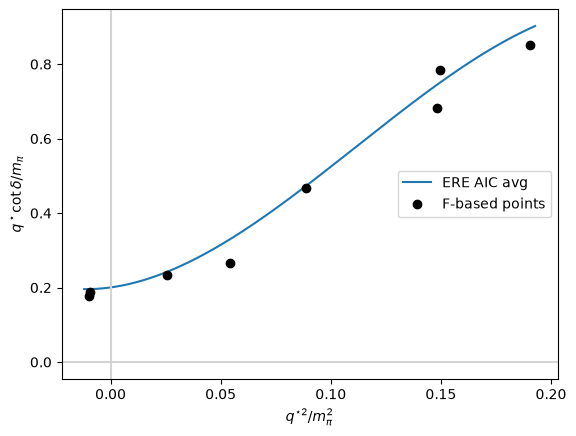

In [20]:
def f_based_points():
    xs, ys = [], []
    for lev in deuteron_levels:
        E   = lev["Ecm_boot"][0]                       # central value
        nP  = Psq_to_nP[lev["d2"]]
        F   = F_function(E, nP, alpha, 48.0)
        rho = phase_space(E**2 + 1j * 1e-16)           # same eps as F_function
        F_pv = np.real(F - 1j * rho)                   # NOT F.real: matters below threshold
        xs.append(lev["q2_boot"][0])                   # q*^2, lattice units
        ys.append(-8 * np.pi * E * F_pv / xi)          # q cot(delta), lattice units
    return np.array(xs), np.array(ys)
 
pts_q2, pts_qcd = f_based_points()
 
# sanity check: these 8 points should sit on the published ERE curve
c0, c1, c2, c3 = 0.0622616, 2.60914, 1154.79, -35746.4
ERE_lat = c0 + c1*q_star_sq_grid + c2*q_star_sq_grid**2 + c3*q_star_sq_grid**3
plt.plot(q_star_sq_grid/m_pi**2, ERE_lat/m_pi, label="ERE AIC avg")
plt.plot(pts_q2/m_pi**2, pts_qcd/m_pi, "ko", label="F-based points")
plt.axhline(0, color="lightgray"); plt.axvline(0, color="lightgray")
plt.xlabel(r"$q^{\star2}/m_\pi^2$"); plt.ylabel(r"$q^\star\cot\delta/m_\pi$")
plt.legend(); plt.show()

Stage 2.
    -

In [21]:
# def k_inv_Grid(Ecm, sigma, length_scale, f_values): #we are deliberately not using the covariance term
#     k, k_inv, logdet, interp_grid = kernel_matrix(knots,knots,sigma,length_scale)
#     k_inv_grid = interp_grid @ f_values
#     return k_inv_grid

def qCotDelta_Grid(x, sigma, length_scale,mu, f_values): #we are deliberately not using the covariance term
    k, k_inv, logdet, interp_grid = kernel_matrix(x,knots,sigma,length_scale)
    qCotDelta_Grid = mu + interp_grid @ (f_values-mu)
    return qCotDelta_Grid


Stage 3:
Using GP curve in place of ERE in Luscher Quantization Formula

In [22]:
rho_grid = np.array([phase_space(E**2 + 1j*1e-16) for E in Ecm_grid])  # same eps as F_function

F_pv_by_Psq = {key: np.real(Fvals - 1j*rho_grid)
               for key, Fvals in F_by_Psq.items()}

def find_Zeros_GPR(f_values, sigma, length_scale, L, Psq, qCotDelta_Grid):
    qcd_conversion = 8 *np.pi * Ecm_grid / xi
    Q = qCotDelta_Grid + (qcd_conversion*F_pv_by_Psq[(L, Psq)])
    poles = free_particle_poles_cached(Psq_to_nP[Psq], 48, m, E_min, E_max)
    return find_zeros_in_grid(Q, Ecm_grid, poles, Psq)

Stage 4

In [23]:
cov_epsilion = 1e-9
def build_observed_data(levels, L):
    """
    levels: list of dicts (raw_levels, or the 8 combined deuteron levels),
            each with 'Psq_tot', 'level_index', and a 'q2_boot' bootstrap array
            (index 0 = central value, 1: = replicas).
    Returns a fixed-order channel dataset for use in log_likelihood.
    """
    obs, cov = build_covariance(levels, key="q2_boot")
    cov_reg = cov + np.eye(len(cov)) * cov_epsilion
    cov_inv = np.linalg.inv(cov_reg)
    sector_keys = [(lvl["d2"], lvl["level_index"]) for lvl in levels]
    return {"L": L, "sector_keys": sector_keys, "obs": obs, "cov_inv": cov_inv}, cov_reg

observed_cache_deuteron,cov_reg_deuteron = build_observed_data(deuteron_levels,48)


def rows_from_combined_levels(Eboot_combined, Psq_combined, level_index_combined):
    """
    Eboot_combined: (n_groups, N_boot) bootstrap CM-energy matrix, index 0 = central value.
    Psq_combined: list of Psq_tot, one per group, in the same order as Eboot_combined's rows.
    """
    n_groups = Eboot_combined.shape[0]
    if level_index_combined is None:
        counts = {}
        level_index_combined = []
        for psq in Psq_combined:
            level_index_combined.append(counts.get(psq, 0))
            counts[psq] = counts.get(psq, 0) + 1

    levels = []
    for g in range(n_groups):
        Ecm_boot_g = Eboot_combined[g]                       # (N_boot,)
        q2_boot_g = (Ecm_boot_g**2/4 - m**2)        # elementwise, same convention as raw_levels
        levels.append({
            "Psq_tot": Psq_combined[g],
            "level_index": level_index_combined[g],
            "q2_boot": q2_boot_g,
        })
    return levels


big_penalty = -1e6
count_mismatch_penalty = -25.0
duplicate_match_penatly = -50.0



In [24]:
# def log_likelihood(f_values, sigma, length_scale, channel_data, Kinv):
#     # L = channel_data["L"]
#     L = 48
#     sector_keys = channel_data["sector_keys"]   # [(Psq, level_index), ...] fixed order
#     obs = channel_data["obs"]                   # q*2, same order as sector_keys
#     cov_inv = channel_data["cov_inv"]

#     # punit2 = (2 * np.pi / L) ** 2
#     needed_Psq = sorted(set(psq for psq, _ in sector_keys))

#     pred_by_sector = {}
#     penalty = 0.0
#     for Psq in needed_Psq:
#         pred_by_sector[Psq] = np.sort(find_Zeros_GPR(f_values, sigma, length_scale, L, Psq, Kinv))

#     needed_by_sector = {}
#     for psq, _ in sector_keys:
#         needed_by_sector[psq] = needed_by_sector.get(psq, 0) + 1

#     for Psq in needed_Psq:
#         n_needed = needed_by_sector[Psq]
#         n_found = len(pred_by_sector[Psq])
#         penalty += count_mismatch_penalty * abs(n_found - n_needed)

#     pred = np.empty_like(obs)
#     matched_idx_by_sector = {}

#     for i, (Psq, level_index) in enumerate(sector_keys):
#         E_pred_arr = pred_by_sector[Psq]
#         E_pred_arr = (E_pred_arr/2)**2 - m**2
#         if(len(E_pred_arr)==0):
#             return big_penalty + penalty, np.inf
#         target_Ecm_obs = obs[i]
#         nearest_idx = np.argmin(np.abs(E_pred_arr - target_Ecm_obs))
#         E_pred = E_pred_arr[nearest_idx]
#         pred[i] = E_pred

#         matched_idx_by_sector.setdefault(Psq,[]).append(nearest_idx)
#     for Psq,idxs in matched_idx_by_sector.items():
#         n_claims = len(idxs)
#         n_unique = len(set(idxs))
#         penalty += duplicate_match_penatly * (n_claims-n_unique)

#     delta = pred - obs
#     # instead of: chi_squared = delta @ cov_inv @ delta
#     chi_squared = delta @ cov_inv @ delta
#     return -0.5 * chi_squared + penalty, chi_squared
    

def log_likelihood(f_values, sigma, length_scale, channel_data, Kinv):
    L = 48
    sector_keys = channel_data["sector_keys"]   
    obs = channel_data["obs"]                   
    cov_inv = channel_data["cov_inv"]

    needed_Psq = sorted(set(psq for psq, _ in sector_keys))

    pred_by_sector = {}
    for Psq in needed_Psq:
        # find_Zeros_GPR returns Ecm, convert to q^2 immediately
        zeros = np.sort(find_Zeros_GPR(f_values, sigma, length_scale, L, Psq, Kinv))
        pred_by_sector[Psq] = (zeros / 2)**2 - m**2

    pred = np.empty_like(obs)
    
    for i, (Psq, level_index) in enumerate(sector_keys):
        q2_pred_arr = pred_by_sector[Psq]
        
        # THE FIX: Match strictly by level_index, exactly like chi2_c!
        if level_index >= len(q2_pred_arr):
            return -1e6, np.inf   # Not enough roots found
            
        pred[i] = q2_pred_arr[level_index]

    delta = pred - obs
    chi_squared = delta @ cov_inv @ delta
    
    return -0.5 * chi_squared, chi_squared

Stage 5:

In [25]:
def log_prior(f_values, sigma, length_scale, mu):
    C, C_inv, logdet, _ = kernel_matrix(knots, knots, sigma, length_scale)
    log_prior = -0.5 * (f_values-mu).T @ C_inv @ (f_values-mu) - 0.5 * logdet - (num_knots / 2) * np.log(2 * np.pi)
    return log_prior

knot_spacing = (q2_max - q2_min) / (num_knots -1)
# sigma_min, sigma_max = 0.01,1
# lc_min, lc_max = 0.001,0.02
# mu_min,mu_max = -3,3

sigma_min, sigma_max = 0.0005, 13     
lc_min, lc_max = 0.0005, 2      
mu_min, mu_max = -4, 2            

def log_hyperprior(sigma, length_scale,mu):
    if not (sigma_min <= sigma <= sigma_max and lc_min <= length_scale <= lc_max and mu_min<mu<mu_max):
        return -np.inf
    return -np.log(sigma_max - sigma_min) - np.log(lc_max - lc_min) - np.log(mu_max-mu_min)

def log_posterior(f_values, sigma, length_scale, observed_cache):
    '''
    log_hyperprior_val = log_hyperprior(sigma, length_scale)
    if not np.isfinite(log_hyperprior_val):
        return -np.inf
    log_prior_val = log_prior(f_values, sigma, length_scale)
    log_likelihood_val = log_likelihood(f_values, sigma, length_scale, observed_cache)
    '''
    C, C_inv, logdet, interp_grid = kernel_matrix(knots, knots, sigma, length_scale)
    log_prior_val = -0.5 * f_values.T @ C_inv @ f_values - 0.5*logdet - 0.5*num_knots *np.log(2*np.pi)

    Kinv = qCotDelta_Grid(q_star_sq_grid, sigma, length_scale, f_values)
    log_likelihood_val, chi_squared = log_likelihood(f_values, sigma, length_scale, observed_cache,Kinv)

    log_hyperprior_val = log_hyperprior(sigma, length_scale)

    return log_prior_val + log_likelihood_val + log_hyperprior_val

def posterior_components(f_values, sigma, length_scale, mu, observed_cache):        
    C, C_inv, logdet, interp_grid = kernel_matrix(knots, knots, sigma, length_scale)
    log_prior_val = -0.5 * (f_values-mu).T @ C_inv @ (f_values-mu) - 0.5*logdet - 0.5*num_knots *np.log(2*np.pi)

    Kinv = qCotDelta_Grid(q_star_sq_grid, sigma, length_scale,mu, f_values)
    log_likelihood_val, chi_squared = log_likelihood(f_values, sigma, length_scale, observed_cache, Kinv)

    log_hyperprior_val = log_hyperprior(sigma, length_scale,mu)

    return log_prior_val, log_likelihood_val, log_hyperprior_val, chi_squared

In [26]:
diag_vals = np.diag(cov_reg_deuteron)
print(sorted(diag_vals))
# e.g.: [4.qCotDelta_Gride-15, 3.36e-10, 5.10e-10, 7.59e-09, 2.92e-08, 6.23e-08, 8.23e-08]

# pick epsilon somewhere below the smallest "real" variance (3.36e-10 here),
# but well above the pathological 4.11e-15
epsilon = 1e-10
for eps in [1e-12, 1e-11, 1e-10, 1e-9, 1e-8]:
    cov_reg_deuteron = cov_reg_deuteron + np.eye(len(cov_reg_deuteron)) * eps
    print(f"eps={eps:.0e}  cond={np.linalg.cond(cov_reg_deuteron):.3e}")

[np.float64(6.9712843841530696e-09), np.float64(1.2361310656662762e-08), np.float64(1.8647366362417336e-08), np.float64(2.675665204838544e-08), np.float64(2.9358513466111294e-08), np.float64(5.3167196629282705e-08), np.float64(7.072142659515367e-08), np.float64(1.5040047302628387e-07)]
eps=1e-12  cond=3.134e+01
eps=1e-11  cond=3.128e+01
eps=1e-10  cond=3.070e+01
eps=1e-09  cond=2.593e+01
eps=1e-08  cond=1.056e+01


In [27]:
knot_spacing = (q2_max - q2_min) / (num_knots - 1)
print(f"num_knots={num_knots}, domain width={q2_max - q2_min:.4f}, spacing={knot_spacing:.5f}")
knots_current = np.linspace(q2_min, q2_max, num_knots)
lc_candidates = np.linspace(knot_spacing*0.5, knot_spacing*5, 30)
for ls in lc_candidates:
    K = RBC_kernel(knots_current, knots_current, 0.03, ls)
    print(f"length_scale={ls:.5f}  cond={np.linalg.cond(K):.3e}")

num_knots=7, domain width=0.0198, spacing=0.00330
length_scale=0.00165  cond=1.666e+00
length_scale=0.00216  cond=3.635e+00
length_scale=0.00267  cond=9.369e+00
length_scale=0.00318  cond=2.692e+01
length_scale=0.00369  cond=8.218e+01
length_scale=0.00421  cond=2.549e+02
length_scale=0.00472  cond=7.763e+02
length_scale=0.00523  cond=2.271e+03
length_scale=0.00574  cond=6.310e+03
length_scale=0.00625  cond=1.658e+04
length_scale=0.00676  cond=4.124e+04
length_scale=0.00727  cond=9.729e+04
length_scale=0.00779  cond=2.184e+05
length_scale=0.00830  cond=4.686e+05
length_scale=0.00881  cond=9.643e+05
length_scale=0.00932  cond=1.910e+06
length_scale=0.00983  cond=3.654e+06
length_scale=0.01034  cond=6.773e+06
length_scale=0.01086  cond=1.219e+07
length_scale=0.01137  cond=2.137e+07
length_scale=0.01188  cond=3.655e+07
length_scale=0.01239  cond=6.113e+07
length_scale=0.01290  cond=1.001e+08
length_scale=0.01341  cond=1.608e+08
length_scale=0.01392  cond=2.538e+08
length_scale=0.01444  con

Stage 6(single chain)

In [28]:
import numpy as np
rng = np.random.default_rng()

move_types = ["knot", "all_knots", "log_length_scale", "log_sigma",'mu']


def propose_new_step(current_state, step_size):
    f_values, sigma, length_scale, mu = current_state
    move = rng.random()
    
    if move < 0.25:
        k = rng.integers(0, len(f_values))
        f_copy = f_values.copy()
        f_copy[k] += step_size["knot"] * rng.normal()
        return (f_copy, sigma, length_scale,mu),0.0,"knot"

    elif move < 0.4:
        f_new = f_values + step_size["all_knots"] * rng.normal(size=len(f_values))
        return (f_new, sigma, length_scale,mu), 0.0,"all_knots"

    elif move < 0.65:
        log_length_scale_new = np.log(length_scale) + step_size["log_length_scale"] * rng.normal()
        length_scale_new = np.exp(log_length_scale_new)
        log_q_correction = np.log(length_scale_new) - np.log(length_scale)   # Hastings correction
        return (f_values, sigma, length_scale_new,mu), log_q_correction,"log_length_scale"
    elif move <0.85:
        mu_new = mu + step_size['mu'] * rng.normal()
        log_q_correction = 0.0
        return (f_values,sigma,length_scale,mu_new),log_q_correction, "mu"
    else:
        # random walk in log(sigma)
        log_sigma_new = np.log(sigma) + step_size["log_sigma"] * rng.normal()
        sigma_new = np.exp(log_sigma_new)
        log_q_correction = np.log(sigma_new) - np.log(sigma)
        return (f_values, sigma_new, length_scale,mu), log_q_correction, "log_sigma"

def acceptance_step(current_state, log_posterior_current, log_posterior_function, step_sizes):
    proposed_state, log_q_correction, type = propose_new_step(current_state, step_sizes)
    log_posterior_proposed = log_posterior_function(*proposed_state)

    log_ratio = log_posterior_proposed - log_posterior_current + log_q_correction
    if np.log(rng.random()) < log_ratio:
        return proposed_state, log_posterior_proposed, True, type
    else:
        return current_state, log_posterior_current, False, type


Covariance Matrix

det[K^-1 + F] = 0

Stage 6: Multi Chain:

In [29]:
# obs, cov = build_covariance(combined_level_dicts, key="q2_boot")
# print("diag(cov):", np.diag(cov))
# print("condition number:", np.linalg.cond(cov))
# print("sqrt(diag(cov)):", np.sqrt(np.diag(cov)))  # rough per-level uncertainty scale

In [30]:
#betas = np.array([0.0, 0.02, 0.04, 0.08, 0.15, 0.20, 0.32, 0.50,0.61,0.71, 0.8,0.9, 1.0])
betas = np.array([0.0, 0.04, 0.08, 0.15, 0.25, 0.32, 0.45, 0.50,0.54, 0.58,0.61, 0.65, 0.68,0.71, 0.76,0.8, 0.85, 0.88,0.93,0.95 ,1.0])

n_chains = len(betas)
best_chi_squared = np.inf


def log_tempered_target(f_knots, sigma, length_scale,mu, beta, observed_cache):
    logprior, loglike, loghyper, chi_squared = posterior_components(f_knots, sigma, length_scale,mu, observed_cache)
    logpost = loglike+logprior+loghyper
    if not np.isfinite(logpost):
        return -np.inf, loglike, logprior, chi_squared
    return beta*loglike + logprior + loghyper, loglike, logprior, chi_squared #loghyper might be removable, but I keep it for now to be safe.

def chain_step(chain_state, chain_logtarget, beta, step_sizes, observed_cache):
    global best_chi_squared

    proposed_state, log_q_correction, move_type = propose_new_step(chain_state, step_sizes)
    proposed_val, loglike, logprior, chi_squared = log_tempered_target(*proposed_state, beta, observed_cache)

    log_ratio = proposed_val - chain_logtarget + log_q_correction

    if(np.log(rng.random()) < log_ratio):
        if(chi_squared < best_chi_squared):
            best_chi_squared = chi_squared
        return proposed_state, proposed_val, True, move_type,chi_squared
    else:
        
        return chain_state, chain_logtarget, False, move_type,chi_squared

def try_swap(c, chains_state, chains_logtarget, betas, observed_cache):
    beta_a, beta_b = betas[c], betas[c+1]
    _, loglike_a, logprior_a, _ = log_tempered_target(*chains_state[c], beta_a, observed_cache)
    _, loglike_b, logprior_b, _ = log_tempered_target(*chains_state[c+1], beta_b, observed_cache)

    log_swap_ratio = (beta_a - beta_b) * (loglike_b - loglike_a)
    if(np.log(rng.random())) < log_swap_ratio:
        chains_state[c], chains_state[c+1] = chains_state[c+1], chains_state[c]
        chains_logtarget[c], _, _, _ = log_tempered_target(*chains_state[c], beta_a, observed_cache)
        chains_logtarget[c+1], _, _, _ = log_tempered_target(*chains_state[c+1], beta_b, observed_cache)
        return True
    return False

In [31]:


# def initialize_chains(observed_cache):
#     chains_state = []
#     chains_logtarget = []
#     for c in range(n_chains):
#         best_state, best_posterior = None, -np.inf
#         for attempt in range(20):
#             sigma0 = rng.uniform(sigma_min, sigma_max)
#             ell0 = rng.uniform(lc_min, lc_max)
#             mu0 = rng.uniform(mu_min, mu_max)
            
#             # THE FIX: Start f0 perfectly flat at mu0 so the length scale can breathe
#             C, _, _, _ = kernel_matrix(knots, knots, sigma0, ell0)
#             Lchol = np.linalg.cholesky(C)

#             f0 = mu0 + Lchol @ rng.normal(size=num_knots)            
#             posterior, _ , _ , _ = log_tempered_target(f0, sigma0, ell0,mu0, betas[c], observed_cache)
#             if posterior > best_posterior:
#                 best_state, best_posterior = (f0, sigma0, ell0, mu0), posterior
#         chains_state.append(best_state)
#         chains_logtarget.append(best_posterior)
#     return chains_state, chains_logtarget

def initialize_chains(observed_cache):
    # straight-line fit through the 8 points, evaluated at the knots
    slope, icpt = np.polyfit(pts_q2, pts_qcd, 1)
    f_line = icpt + slope * knots                      # knots are in q*^2 (lattice units)
 
    mu0    = f_line.mean()
    sigma0 = 0.3                                       # same order as f_line's spread about its mean
    ell0   = 3 * knot_spacing                          # smooth, but not near-singular
 
    chains_state, chains_logtarget = [], []
    for c in range(n_chains):
        f0 = f_line + 1e-3 * rng.normal(size=num_knots)   # tiny jitter so chains aren't identical
        state = (f0, sigma0, ell0, mu0)
        post, _, _, chi2 = log_tempered_target(*state, betas[c], observed_cache)
        if c == n_chains - 1:
            print(f"cold chain start: chi2 = {chi2:.2f}, log target = {post:.2f}")
        chains_state.append(state)
        chains_logtarget.append(post)
    return chains_state, chains_logtarget
 
 

In [32]:
def run_parallel_tempering(observed_cache, n_steps, burn_in):
    cold = n_chains - 1
    thin = 5
    swap_every = 10

    # multi_chain_sizes = {
    #     "knot": 0.002,       
    #     "all_knots": 0.0008,  
    #     "log_length_scale": 0.15,    
    #     "log_sigma": 0.25,
    #     "mu":0.025}

    multi_chain_sizes = {
        "knot":            3e-3,
        "all_knots":       3e-3,
        "log_length_scale": 0.05,
        "log_sigma":        0.05,
        "mu":              3e-3,
    }

    samples = []
    swap_attempts = np.zeros(n_chains-1)
    swap_accepts = np.zeros(n_chains-1)
    cold_log_post_history = []
    # chi_squared_history = []
    cold_accepted_by_type = {t: 0 for t in move_types}
    cold_proposed_by_type = {t: 0 for t in move_types}
    best_cold_state, best_cold_logpost = None, -np.inf
    best_cold_chi_squared = np.inf

    chains_state, chains_logtarget = initialize_chains(observed_cache)

    for step in range(n_steps):
        for c in range(n_chains):
            chains_state[c], chains_logtarget[c], accepted, move_type , chi_squared= chain_step(
                chains_state[c], chains_logtarget[c], betas[c], multi_chain_sizes, observed_cache
            )

            if c == cold:
                cold_log_post_history.append(chains_logtarget[c])
                if chains_logtarget[c] > best_cold_logpost:
                        best_cold_state, best_cold_logpost = chains_state[c], chains_logtarget[c]
                if step >= burn_in:
                    cold_proposed_by_type[move_type] += 1
                    if accepted:
                        cold_accepted_by_type[move_type] += 1
                    if accepted and chi_squared < best_cold_chi_squared:
                        best_cold_chi_squared = chi_squared

        if((step+1) % swap_every == 0):   
            for c in range(n_chains - 1):
                swap_attempts[c] += 1
                if try_swap(c, chains_state, chains_logtarget, betas, observed_cache):
                    swap_accepts[c] += 1

        if step >= burn_in and step % thin == 0:
            samples.append(chains_state[cold])   

        if (step+1) % 1000 == 0:
            print(f"Step {step+1}/{n_steps} completed. Cold chain log posterior: {chains_logtarget[cold]:.3f}")
    return samples, swap_attempts, swap_accepts, cold_log_post_history, cold_accepted_by_type, cold_proposed_by_type, best_cold_state, best_cold_logpost, best_cold_chi_squared

In [33]:
import itertools

sector_keys = [(L, Psq) for L in L_values for Psq in Psq_to_nP.keys()]
color_cycle = plt.cm.tab10.colors   
color_by_sector = {key: color_cycle[i % len(color_cycle)] for i, key in enumerate(sector_keys)}

def plot_mcmc( best_cold_state, cold_log_post_history, samples):
    best_f_knots,  best_sigma ,best_length_scale,best_mu= best_cold_state 

    q_star_sq_grid = np.linspace(q2_min , q2_max ,2000)

    a_true, r_true, p4_true = a_r_Values[0]


    q_cot_delta = a_true + r_true*q_star_sq_grid + p4_true*q_star_sq_grid**2
    m_pi = 0.310810


    # Kinv = xi * q_cot_delta / (8*np.pi*Ecm_grid)
    true_curve_at_knots = 1/a_true + 0.5*r_true*((knots/2)**2 - m**2)
    # ll,lp,lh = posterior_components(true_curve_at_knots, best_length_scale,best_sigma ,observed_cache)

    skip = 1000  # adjust based on how many steps it takes to stabilize
    plt.plot(cold_log_post_history[skip:])
    plt.xlabel("step")
    plt.ylabel("cold chain log posterior")
    # plt.axhline(ll+lp+lh, color="red", linestyle="--", label="true curve")
    plt.legend()
    plt.show()


    # posterior_mean = curves.mean(axis=0)
    # lower_68 = np.percentile(curves, 16, axis=0)
    # upper_68 = np.percentile(curves, 84, axis=0)

    reconstructed_curve = qCotDelta_Grid(q_star_sq_grid, best_sigma, best_length_scale,best_mu, best_f_knots)  
    c0 = 0.0622616
    c1 = 2.60914
    c2 = 1154.79
    c3 = -35746.4

    # Evaluate the polynomial across your grid
    ERE = c0 + (c1 * q_star_sq_grid) + (c2 * q_star_sq_grid**2) + (c3 * q_star_sq_grid**3)

    curves = np.array([
        qCotDelta_Grid(q_star_sq_grid, sigma, length_scale, mu, f_knots)  #* qcd_conversion
        for f_knots, sigma, length_scale, mu in samples
    ])

    posterior_median_qcd = np.median(curves,axis=0)
    lower_68_qcd = np.percentile(curves, 16, axis=0)
    upper_68_qcd = np.percentile(curves, 84, axis=0)




    x_all = q_star_sq_grid / m_pi**2
    xlo, xhi = -0.02, 0.20
    sel = (x_all > xlo) & (x_all < xhi)

    kx = knots / m_pi**2
    ksel = (kx > xlo) & (kx < xhi)          # separate mask for the 7 knots

    plt.figure(figsize=(8, 5))
    plt.plot(x_all[sel], ERE[sel]/m_pi,  label="Hidden ERE truth")   
    plt.plot(x_all[sel], posterior_median_qcd[sel]/m_pi,  label="Reconstructed curve")   
    plt.xlim(-0.02, 0.20)
    plt.xlabel(r"$q^{*2}$")
    plt.scatter(knots/ m_pi**2, best_f_knots/ m_pi, zorder=5)
    plt.ylabel(r"$q^*\cot\delta$")
    plt.title(r"$q^*\cot\delta$ reconstruction")
    plt.legend()
    plt.show()




    plt.figure(figsize=(8, 5))
    plt.plot(x_all[sel], ERE[sel]/m_pi, label="ERE AIC avg")
    plt.plot(x_all[sel], posterior_median_qcd[sel]/m_pi, label="GP median")
    plt.fill_between(x_all[sel], lower_68_qcd[sel]/m_pi, upper_68_qcd[sel]/m_pi,
                    alpha=0.3, label="68% interval")
    plt.scatter(kx[ksel], best_f_knots[ksel]/m_pi, zorder=5, color="tab:orange", label="knots")
    plt.axhline(0, color="lightgray"); plt.axvline(0, color="lightgray")
    plt.xlim(xlo, xhi)
    plt.xlabel(r"$q^{\star2}/m_\pi^2$"); plt.ylabel(r"$q^\star\cot\delta/m_\pi$")
    plt.legend(); 
    plt.show()
    


In [34]:
# plot_mcmc(observed_cache_0, best_cold_state_diag, cold_log_post_history_diag, samples_diag)

In [35]:
(samples_cov, swap_attempts_cov, swap_accepts_cov, cold_log_post_history_cov,
 cold_accepted_by_type_cov, cold_proposed_by_type_cov, best_cold_state_cov, best_cold_logpost_cov, best_cold_chi_squared
) = run_parallel_tempering(observed_cache_deuteron, n_steps=15000, burn_in=5000)

cold chain start: chi2 = 12.52, log target = -2.72
Step 1000/15000 completed. Cold chain log posterior: 11.147
Step 2000/15000 completed. Cold chain log posterior: 13.932
Step 3000/15000 completed. Cold chain log posterior: 15.463
Step 4000/15000 completed. Cold chain log posterior: 18.364
Step 5000/15000 completed. Cold chain log posterior: 13.763
Step 6000/15000 completed. Cold chain log posterior: 12.788
Step 7000/15000 completed. Cold chain log posterior: 10.173
Step 8000/15000 completed. Cold chain log posterior: 21.017
Step 9000/15000 completed. Cold chain log posterior: 16.177
Step 10000/15000 completed. Cold chain log posterior: 22.623
Step 11000/15000 completed. Cold chain log posterior: 17.391
Step 12000/15000 completed. Cold chain log posterior: 12.405
Step 13000/15000 completed. Cold chain log posterior: 15.696
Step 14000/15000 completed. Cold chain log posterior: 9.256
Step 15000/15000 completed. Cold chain log posterior: 14.640


C:\Users\shing\AppData\Local\Temp\ipykernel_34044\2396518815.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


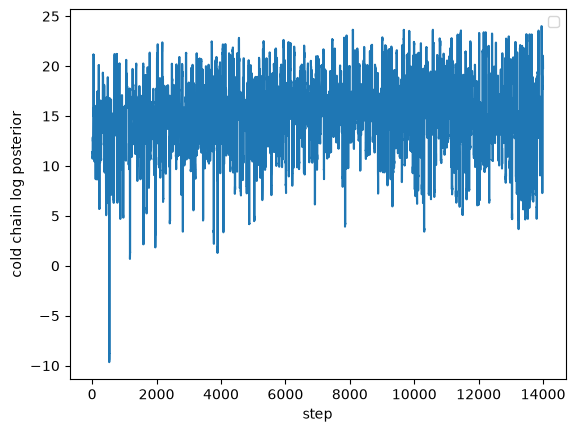

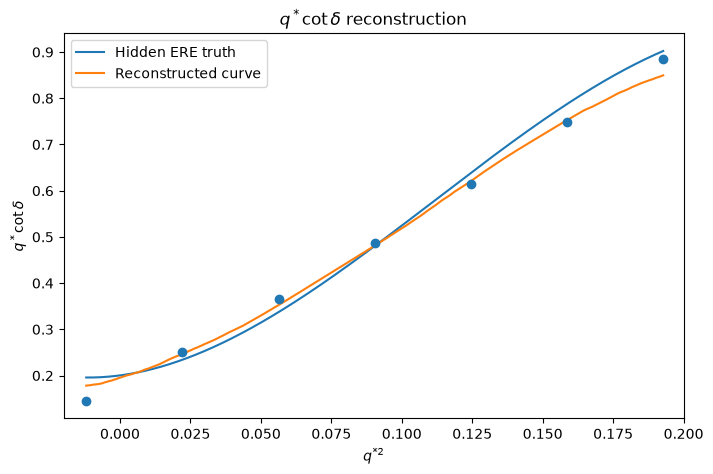

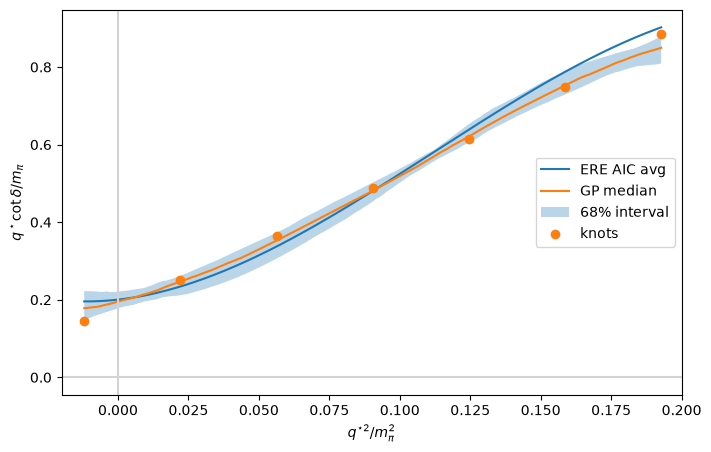

In [42]:
plot_mcmc(best_cold_state_cov, cold_log_post_history_cov, samples_cov)

In [37]:
print(f"Best Chi Squared: {best_cold_chi_squared}")


Best Chi Squared: 4.112782025329482


In [38]:
swap_rates = swap_accepts_cov/swap_attempts_cov
for i, rate in enumerate(swap_rates):
    print(f"({betas[i]:.3f}, {betas[i+1]:.3f}): {rate:.4f}")

(0.000, 0.040): 0.5640
(0.040, 0.080): 0.9293
(0.080, 0.150): 0.9033
(0.150, 0.250): 0.8973
(0.250, 0.320): 0.9440
(0.320, 0.450): 0.8853
(0.450, 0.500): 0.9593
(0.500, 0.540): 0.9727
(0.540, 0.580): 0.9647
(0.580, 0.610): 0.9700
(0.610, 0.650): 0.9707
(0.650, 0.680): 0.9613
(0.680, 0.710): 0.9773
(0.710, 0.760): 0.9647
(0.760, 0.800): 0.9700
(0.800, 0.850): 0.9607
(0.850, 0.880): 0.9813
(0.880, 0.930): 0.9567
(0.930, 0.950): 0.9880
(0.950, 1.000): 0.9713


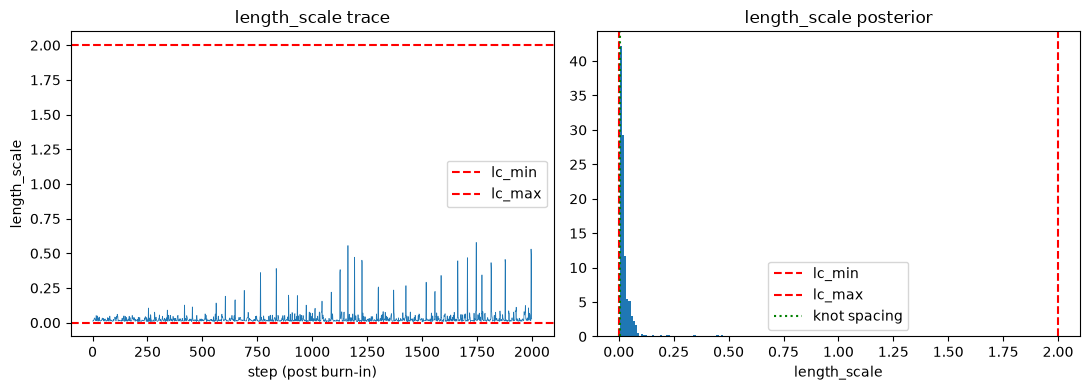

length_scale posterior: median=0.01741, 16-84%=[0.01194, 0.04334]
bounds: lc_min=0.0005, lc_max=2, knot_spacing=0.00330
fraction of samples within 5% of lc_min: 0.00%


In [39]:
import matplotlib.pyplot as plt

# 1. No need to slice out burn-in, the tempering function already discarded it.
# 2. Extract the length_scale (index 2) from the 4-tuple (f_values, sigma, length_scale, mu)
length_scale_chain = [state[2] for state in samples_cov]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# left: trace, so you can see if it's still wandering or has settled
axs[0].plot(length_scale_chain, lw=0.5)
axs[0].axhline(lc_min, color='r', ls='--', label='lc_min')
axs[0].axhline(lc_max, color='r', ls='--', label='lc_max')
axs[0].set_xlabel('step (post burn-in)')
axs[0].set_ylabel('length_scale')
axs[0].legend()
axs[0].set_title('length_scale trace')

# right: marginal posterior vs the bounds
axs[1].hist(length_scale_chain, bins=60, density=True)
axs[1].axvline(lc_min, color='r', ls='--', label='lc_min')
axs[1].axvline(lc_max, color='r', ls='--', label='lc_max')
axs[1].axvline(knot_spacing, color='g', ls=':', label='knot spacing')
axs[1].set_xlabel('length_scale')
axs[1].set_title('length_scale posterior')
axs[1].legend()

plt.tight_layout()
plt.show()

# length_scale_chain is now a standard list, convert to numpy array for the math operations
length_scale_chain = np.array(length_scale_chain)

print(f"length_scale posterior: median={np.median(length_scale_chain):.5f}, "
      f"16-84%=[{np.percentile(length_scale_chain,16):.5f}, {np.percentile(length_scale_chain,84):.5f}]")
print(f"bounds: lc_min={lc_min}, lc_max={lc_max}, knot_spacing={knot_spacing:.5f}")
print(f"fraction of samples within 5% of lc_min: {(length_scale_chain < lc_min*1.05).mean():.2%}")

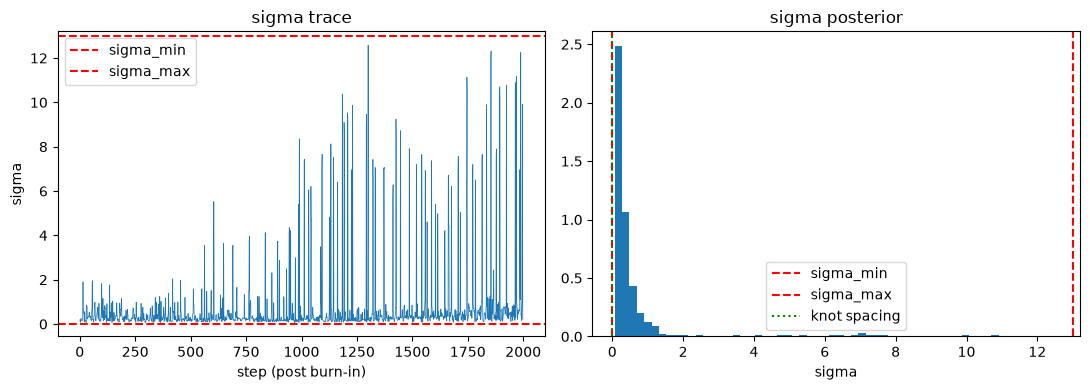

sigma posterior: median=0.26498, 16-84%=[0.14332, 0.73477]
bounds: sigma_min=0.0005, sigma_max=13, knot_spacing=0.00330
fraction of samples within 5% of sigma_min: 0.00%


In [40]:
import matplotlib.pyplot as plt

# 1. No need to slice out burn-in, the tempering function already discarded it.
# 2. Extract the length_scale (index 2) from the 4-tuple (f_values, sigma, length_scale, mu)
sigma_chain = [state[1] for state in samples_cov]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))

# left: trace, so you can see if it's still wandering or has settled
axs[0].plot(sigma_chain, lw=0.5)
axs[0].axhline(sigma_min, color='r', ls='--', label='sigma_min')
axs[0].axhline(sigma_max, color='r', ls='--', label='sigma_max')
axs[0].set_xlabel('step (post burn-in)')
axs[0].set_ylabel('sigma')
axs[0].legend()
axs[0].set_title('sigma trace')

# right: marginal posterior vs the bounds
axs[1].hist(sigma_chain, bins=60, density=True)
axs[1].axvline(sigma_min, color='r', ls='--', label='sigma_min')
axs[1].axvline(sigma_max, color='r', ls='--', label='sigma_max')
axs[1].axvline(knot_spacing, color='g', ls=':', label='knot spacing')
axs[1].set_xlabel('sigma')
axs[1].set_title('sigma posterior')
axs[1].legend()

plt.tight_layout()
plt.show()

# sigma_chain is now a standard list, convert to numpy array for the math operations
sigma_chain = np.array(sigma_chain)

print(f"sigma posterior: median={np.median(sigma_chain):.5f}, "
      f"16-84%=[{np.percentile(sigma_chain,16):.5f}, {np.percentile(sigma_chain,84):.5f}]")
print(f"bounds: sigma_min={sigma_min}, sigma_max={sigma_max}, knot_spacing={knot_spacing:.5f}")
print(f"fraction of samples within 5% of sigma_min: {(sigma_chain < sigma_min*1.05).mean():.2%}")

In [41]:
c = [0.0622616, 2.60914, 1154.79, -35746.4]      # Table V, AIC average
ERE = sum(ci * q_star_sq_grid**i for i, ci in enumerate(c))
ll, chi2 = log_likelihood(None, None, None, observed_cache_deuteron, ERE)
print(chi2)       # expect roughly 4-5

4.674021184898948
